# 03 · Henyelrey Lucio Garcia Chura — Intentos de conexión (SYN)

**Pregunta central del proyecto:** ¿cómo detectar a tiempo comportamientos
anómalos en el tráfico de red del laboratorio para que la mesa de TI reaccione
antes de que se conviertan en incidentes?

**Mi dimensión:** ¿hay intentos de conexión anómalos (escaneos de puertos,
conexiones que nadie responde)?

| | U1 (batch, este notebook) | U2 (streaming, Grafana) |
|---|---|---|
| Indicador | SYN por hora, SYN sin respuesta por host | SYN por minuto |
| Predicción | SYN de la próxima hora | SYN del minuto siguiente |
| Fuente | Data Lake Gold/Silver (TRCU.csv) | Kafka `trafico-flujos` → Spark |

In [1]:
import sys
sys.path.insert(0, "/jobs")
sys.path.insert(0, "/notebooks")

import matplotlib.pyplot as plt
from pyspark.sql import functions as F

from analisis_comun import cargar, metricas_streaming, modelo_horario, perfil_horario, picos, resumen
from comun import crear_spark

spark = crear_spark("nb-03-henyelrey")
silver, gold = cargar(spark)
IND = "syn"

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/10/30 00:51:34 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


## 1. Descriptivo

/usr/local/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


                       syn
minutos       34751.000000
total          4323.000000
promedio_min      0.124399
mediana_min       0.000000
p99_min           4.000000
max_min         138.000000


/usr/local/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


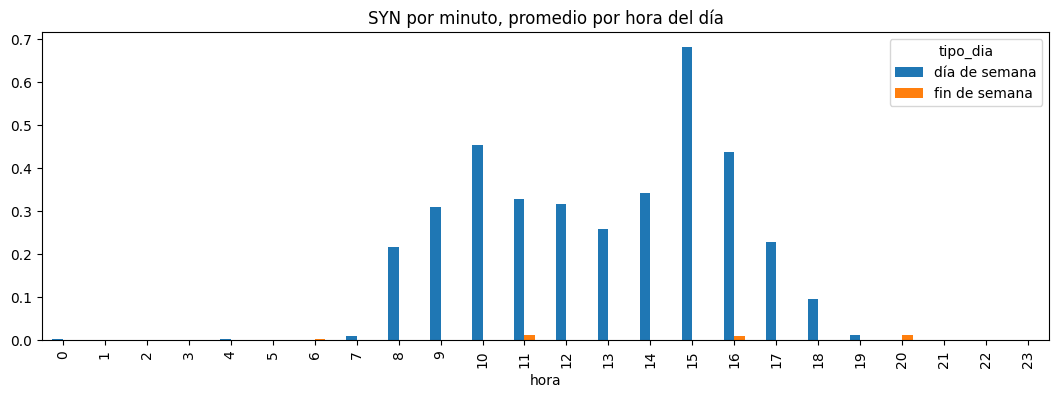

In [2]:
print(resumen(gold, IND).to_string())
perfil_horario(gold, IND).plot(kind="bar", figsize=(13, 4), title="SYN por minuto, promedio por hora del día")
plt.show()

## 2. Diagnóstico: conexiones que nadie responde
Un flujo TCP con SYN y **ningún paquete de vuelta** es un intento fallido:
puerto cerrado, host apagado o, si se repite contra muchos puertos, un escaneo.

In [3]:
tcp = silver.where(F.col("ip_prot") == 6)
sin_respuesta = tcp.where((F.col("syn") >= 1) & (F.col("paquetes_bwd") == 0))
total_syn, fallidos = tcp.where(F.col("syn") >= 1).count(), sin_respuesta.count()
print(f"Flujos TCP con SYN: {total_syn:,} | sin respuesta: {fallidos:,} ({100 * fallidos / max(total_syn, 1):.1f} %)")

Flujos TCP con SYN: 3,207 | sin respuesta: 591 (18.4 %)


In [4]:
# Heurística de escaneo: un mismo origen que toca muchos puertos destino distintos en un minuto.
escaneo = (tcp.withColumn("minuto", F.date_trunc("minute", "ts_inicio"))
           .groupBy("src", "minuto").agg(F.countDistinct("dport").alias("puertos_distintos"),
                                         F.sum("syn").alias("syn"))
           .orderBy(F.desc("puertos_distintos")).limit(10).toPandas())
print("Orígenes (seudonimizados) que tocaron más puertos distintos en un mismo minuto:")
print(escaneo.to_string(index=False))

/usr/local/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


Orígenes (seudonimizados) que tocaron más puertos distintos en un mismo minuto:
           src              minuto  puertos_distintos  syn
h-1f2080ff93ac 2026-08-11 14:13:00                 11    0
h-818bea13be06 2026-07-09 17:36:00                 10    0
h-1f2080ff93ac 2026-08-11 17:44:00                  9    0
h-fe1a1d60ffee 2026-07-02 10:06:00                  8    0
h-88031182e458 2026-08-16 20:16:00                  8    0
h-ccba979e8bf4 2026-07-02 10:02:00                  8    0
h-6fe20025f4e9 2026-07-03 11:13:00                  8    0
h-51b5189a81f9 2026-08-11 14:28:00                  7    0
h-007df3902cbd 2026-08-03 16:07:00                  7    0
h-51b5189a81f9 2026-08-11 15:23:00                  7    0


/usr/local/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


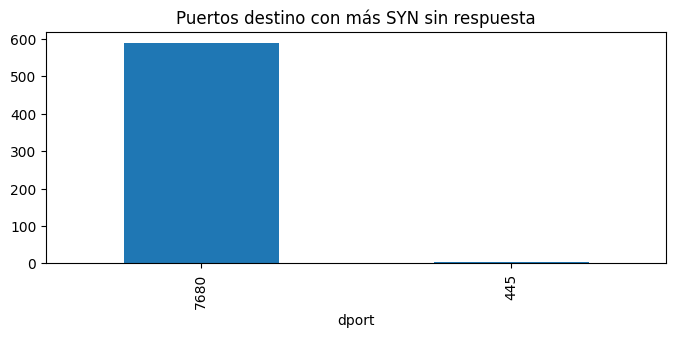

In [5]:
por_puerto = (sin_respuesta.groupBy("dport").count().orderBy(F.desc("count")).limit(10).toPandas())
por_puerto.plot(x="dport", y="count", kind="bar", figsize=(8, 3), legend=False,
                title="Puertos destino con más SYN sin respuesta")
plt.show()

In [6]:
print("Minutos con más SYN de lo normal para su hora:")
print(picos(gold, IND).to_string(index=False))

Minutos con más SYN de lo normal para su hora:


/usr/local/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


     ventana_inicio  syn  media_de_esa_hora    z
2026-08-08 20:10:00    4                0.0 36.6
2026-08-13 23:16:00    1                0.0 36.6
2026-08-12 04:18:00    1                0.0 36.6
2026-08-11 00:33:00    1                0.0 36.6
2026-08-13 16:33:00   94                0.3 36.4
2026-08-07 18:05:00   40                0.1 35.1
2026-07-01 14:59:00   52                0.2 30.8
2026-07-01 15:00:00  138                0.5 30.3
2026-07-08 19:28:00    5                0.0 27.9
2026-08-10 06:04:00    1                0.0 25.9


## 3. Predictivo U1: SYN de la próxima hora (batch)

In [7]:
tabla, horas = modelo_horario(gold, IND)
print(f"{horas} horas consecutivas, división cronológica 80/20")
print(tabla.to_string())

26/10/30 00:51:59 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:51:59 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.


26/10/30 00:52:00 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:52:00 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.


26/10/30 00:52:00 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:52:00 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.


26/10/30 00:52:01 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:52:01 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:52:01 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:52:01 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:52:01 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.


26/10/30 00:52:01 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:52:01 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:52:01 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:52:01 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:52:01 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:52:01 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 0

...

26/10/30 00:52:13 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:52:13 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:52:13 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:52:13 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:52:13 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.


26/10/30 00:52:13 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:52:13 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:52:13 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:52:13 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:52:13 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:52:13 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 0

26/10/30 00:52:14 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:52:14 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:52:14 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:52:14 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:52:14 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.


26/10/30 00:52:14 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:52:14 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:52:14 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:52:14 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:52:14 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:52:14 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 0

740 horas consecutivas, división cronológica 80/20
                     rmse    mae     r2  mejora_vs_persistencia_%
persistencia       21.219  6.993 -0.156                     0.000
linear_regression  18.221  8.054  0.148                    14.127
random_forest      16.920  6.700  0.265                    20.262


## 4. U2: el modelo que corre en vivo (por minuto)

In [8]:
m, test, cv = metricas_streaming(IND)
print(f"Ganador: {m['ganador']} (escala {m['escala']}) | filas: {m['filas_total']:,}")
print(test.to_string())
print("\nBúsqueda de hiperparámetros (RMSE promedio de validación):")
print(cv.head(8).to_string(index=False))
print("\nVariables más importantes:", m["importancia_variables"])

Ganador: gbt (escala log) | filas: 26,316
                    rmse    mae     r2  mejora_vs_persistencia_%
persistencia       1.139  0.254  0.791                      0.00
linear_regression  2.313  0.250  0.136                   -103.07
random_forest      1.976  0.239  0.370                    -73.49
gbt                1.006  0.218  0.837                     11.68

Búsqueda de hiperparámetros (RMSE promedio de validación):
           modelo   escala  regParam  rmse_cv  numTrees  maxDepth  maxIter
              gbt      log       NaN    1.070       NaN       5.0     50.0
              gbt      log       NaN    1.076       NaN       3.0     50.0
    random_forest      log       NaN    1.079      40.0      10.0      NaN
linear_regression      log       0.0    1.080       NaN       NaN      NaN
linear_regression      log       0.1    1.080       NaN       NaN      NaN
    random_forest      log       NaN    1.081      40.0       6.0      NaN
              gbt original       NaN    1.157   

## 5. Conclusiones
- **Línea base tranquila:** 0,12 SYN por minuto en promedio (mediana 0, p99 4),
  con picos aislados de hasta 138 en un minuto.
- **18,4 % de los intentos TCP queda sin respuesta** (591 de 3207): esa es la
  referencia "normal" contra la que se compara un escaneo.
- **No hay escaneos evidentes en el histórico:** el origen que más puertos
  distintos tocó en un mismo minuto llegó a 11. Un escaneo real tocaría
  cientos; este valor sirve de umbral de referencia.
- **U1 (por hora):** el Random Forest mejora 20 % el RMSE frente a la persistencia.
- **U2 (por minuto):** acá la persistencia ya es fuerte (R² 0,79); LR y RF
  quedan PEOR que ella y solo el GBT la supera (+11,7 %). Si el SYN real
  supera la predicción + 3·RMSE, Spark abre solo un incidente **alta / escaneo_red**.